In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models

In [2]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

In [3]:
from pathlib import Path
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=str(Path.home() / ".cache" / "ml-notebooks" / "speech-commands"),
    batch_size=64,
    validation_split=0.3,
    seed=seed,
    output_sequence_length=16000,
    subset='both'
)

Found 6505 files belonging to 4 classes.
Using 4554 files for training.
Using 1951 files for validation.


In [4]:
label = np.array(train_ds.class_names)
print(label)

['follow' 'learn' 'tree' 'visual']


In [5]:
def squeeze(audio, label):
    audio = tf.squeeze(audio, axis=-1)
    return audio, label

def get_spectogram(waveform):
    spectogram = tf.signal.stft(waveform, frame_length=255, frame_step=128)
    spectogram = tf.abs(spectogram)
    spectogram = spectogram[..., tf.newaxis]
    return spectogram

def make_spectogram_ds(ds):
    return ds.map(
        map_func=lambda audio, label: (get_spectogram(audio), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )

In [6]:
train_ds = train_ds.map(squeeze, tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, tf.data.AUTOTUNE)

test_ds = val_ds.shard(num_shards=2, index=0)
val_ds = val_ds.shard(num_shards=2, index=1)

In [7]:
train_spectogram_ds = make_spectogram_ds(train_ds)
val_spectogram_ds = make_spectogram_ds(val_ds)
test_spectogram_ds = make_spectogram_ds(test_ds)

In [8]:
for example_spectogram, example_spectogram_label, in train_spectogram_ds.take(1):
    break

input_shape = example_spectogram.shape[1:]
num_label = len(label)

In [9]:
norm_layer = layers.Normalization()
norm_layer.adapt(
    data=train_spectogram_ds.map(
        map_func=lambda spec, label:spec
    )
)

In [10]:
model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Resizing(32, 32),
    norm_layer,
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.5),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_label)
])

In [11]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (None, 32, 32, 1)         0         
                                                                 
 normalization (Normalizatio  (None, 32, 32, 1)        3         
 n)                                                              
                                                                 
 conv2d (Conv2D)             (None, 30, 30, 64)        640       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 15, 15, 64)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 13, 13, 128)       73856     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 6, 6, 128)        0

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [13]:
history = model.fit(
    train_spectogram_ds,
    validation_data=val_spectogram_ds,
    epochs=8,
    callbacks=tf.keras.callbacks.EarlyStopping(verbose=1, patience=2)
)

Epoch 1/8
72/72 [==============================] - 5s 59ms/step - loss: 0.8249 - accuracy: 0.6706 - val_loss: 0.4847 - val_accuracy: 0.7969
Epoch 2/8
72/72 [==============================] - 3s 41ms/step - loss: 0.5002 - accuracy: 0.8270 - val_loss: 0.3609 - val_accuracy: 0.8760
Epoch 3/8
72/72 [==============================] - 3s 44ms/step - loss: 0.3800 - accuracy: 0.8718 - val_loss: 0.2942 - val_accuracy: 0.8917
Epoch 4/8
72/72 [==============================] - 3s 46ms/step - loss: 0.3203 - accuracy: 0.8904 - val_loss: 0.2464 - val_accuracy: 0.9062
Epoch 5/8
72/72 [==============================] - 4s 47ms/step - loss: 0.2752 - accuracy: 0.9038 - val_loss: 0.2478 - val_accuracy: 0.9156
Epoch 6/8
72/72 [==============================] - 3s 44ms/step - loss: 0.2363 - accuracy: 0.9227 - val_loss: 0.1920 - val_accuracy: 0.9438
Epoch 7/8
72/72 [==============================] - 3s 43ms/step - loss: 0.2112 - accuracy: 0.9269 - val_loss: 0.1649 - val_accuracy: 0.9458
Epoch 8/8
72/72 [===

In [14]:
for i, (spectogram_batch, label_batch) in enumerate(test_spectogram_ds):
    prediction = model.predict(spectogram_batch)

    for j in range(len(label_batch)):
        true_index = label_batch[j].numpy()
        predicted_index = np.argmax(prediction[j])

        print(f'Batch {i}, Data {j}: Original Label -> {label[true_index]}, Prediction -> {label[predicted_index]}')

2/2 [==============================] - 0s 9ms/step
Batch 0, Data 0: Original Label -> tree, Prediction -> tree
Batch 0, Data 1: Original Label -> learn, Prediction -> learn
Batch 0, Data 2: Original Label -> tree, Prediction -> follow
Batch 0, Data 3: Original Label -> follow, Prediction -> follow
Batch 0, Data 4: Original Label -> tree, Prediction -> tree
Batch 0, Data 5: Original Label -> follow, Prediction -> follow
Batch 0, Data 6: Original Label -> follow, Prediction -> follow
Batch 0, Data 7: Original Label -> follow, Prediction -> follow
Batch 0, Data 8: Original Label -> follow, Prediction -> follow
Batch 0, Data 9: Original Label -> learn, Prediction -> learn
Batch 0, Data 10: Original Label -> visual, Prediction -> visual
Batch 0, Data 11: Original Label -> learn, Prediction -> learn
Batch 0, Data 12: Original Label -> tree, Prediction -> tree
Batch 0, Data 13: Original Label -> follow, Prediction -> follow
Batch 0, Data 14: Original Label -> follow, Prediction -> follow
Batc

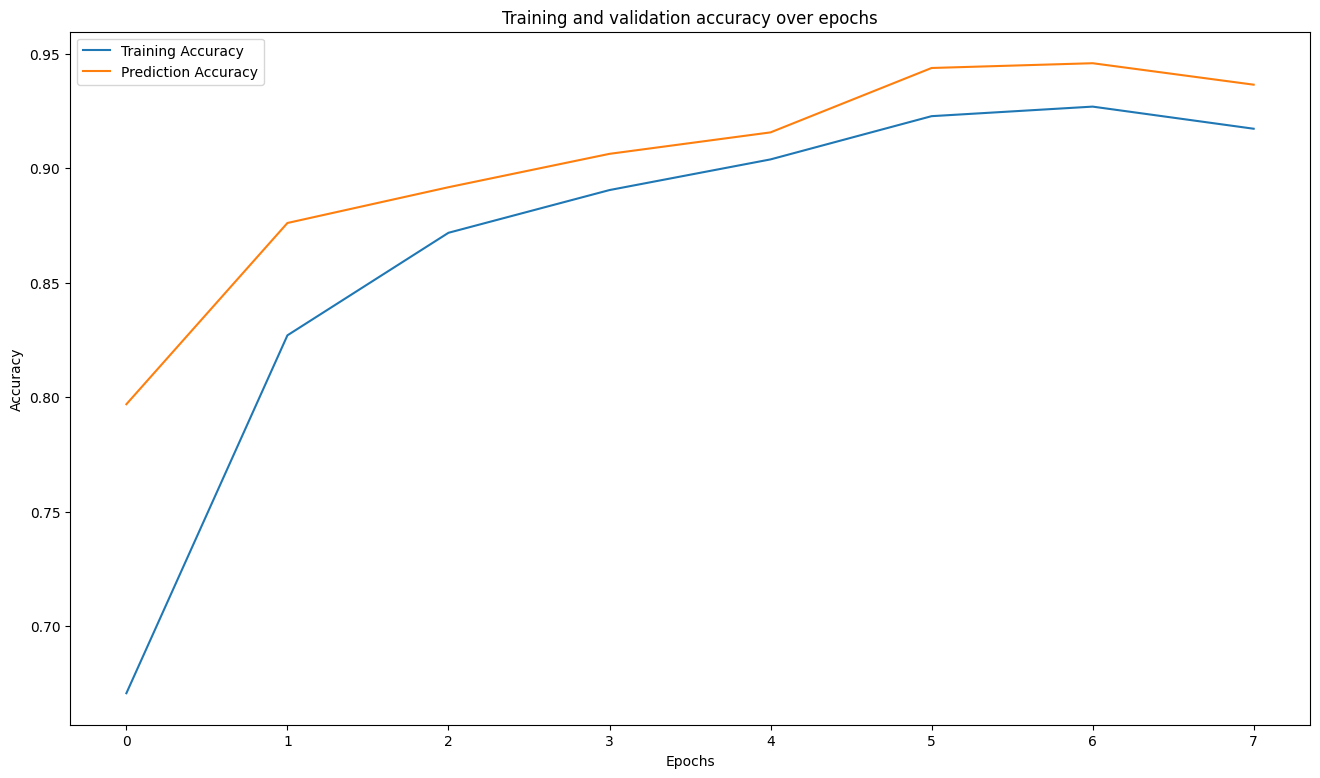

In [15]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch_range = range(len(acc))
plt.figure(figsize=(16, 9))
plt.plot(epoch_range, acc, label='Training Accuracy')
plt.plot(epoch_range, val_acc, label='Prediction Accuracy')
plt.title('Training and validation accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()